# PEPPER trade-round analysis
This notebook analyzes `trades_round_2_day_*` for PEPPER, combining:
- trade print context (slippage, timing, edge),
- trend and residual diagnostics,
- event studies (pullback vs extension),
- execution-aware scorecards.

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 180)

price_files = {
    -2: "../data2/prices_round_2_day_-1.csv",
    -1: "../data2/prices_round_2_day_0.csv",
}

trade_files = {
    -2: "../data2/trades_round_2_day_-1.csv",
    -1: "../data2/trades_round_2_day_0.csv",
}

price_frames = []
trade_frames = []

for day, path in price_files.items():
    frame = pd.read_csv(path, sep=";")
    frame["day"] = day
    price_frames.append(frame)

for day, path in trade_files.items():
    frame = pd.read_csv(path, sep=";")
    frame["day"] = day
    trade_frames.append(frame)

prices = pd.concat(price_frames, ignore_index=True).sort_values(["day", "timestamp"]).reset_index(drop=True)
trades = pd.concat(trade_frames, ignore_index=True).sort_values(["day", "timestamp"]).reset_index(drop=True)

prices.shape, trades.shape

((40000, 17), (1593, 8))

In [11]:
def prepare_product_context(product: str):
    price_cols = [
        "day",
        "timestamp",
        "product",
        "bid_price_1",
        "bid_volume_1",
        "ask_price_1",
        "ask_volume_1",
        "mid_price",
        "profit_and_loss",
    ]
    price_cols = [col for col in price_cols if col in prices.columns]

    price_prod = prices.loc[prices["product"] == product, price_cols].copy().sort_values(["day", "timestamp"])
    price_prod = price_prod[price_prod["mid_price"] > 0].copy()

    if {"bid_price_1", "ask_price_1"}.issubset(price_prod.columns):
        price_prod["spread_1"] = price_prod["ask_price_1"] - price_prod["bid_price_1"]
    else:
        price_prod["spread_1"] = np.nan

    if {"bid_volume_1", "ask_volume_1"}.issubset(price_prod.columns):
        price_prod["depth_1"] = price_prod["bid_volume_1"].abs() + price_prod["ask_volume_1"].abs()
    else:
        price_prod["depth_1"] = np.nan

    price_prod["mid_change_1"] = price_prod.groupby("day")["mid_price"].shift(-1) - price_prod["mid_price"]
    price_prod["mid_change_5"] = price_prod.groupby("day")["mid_price"].shift(-5) - price_prod["mid_price"]
    price_prod["mid_change_25"] = price_prod.groupby("day")["mid_price"].shift(-25) - price_prod["mid_price"]
    price_prod["ret_1"] = price_prod.groupby("day")["mid_price"].pct_change()

    trade_prod = trades.loc[trades["symbol"] == product, ["day", "timestamp", "price", "quantity"]].copy().sort_values(["day", "timestamp"])

    merged_frames = []
    for day in sorted(trade_prod["day"].dropna().unique().tolist()):
        trade_day = trade_prod[trade_prod["day"] == day].sort_values("timestamp")
        price_day = price_prod[price_prod["day"] == day].drop(columns=["day"]).sort_values("timestamp")
        if trade_day.empty or price_day.empty:
            continue
        merged_day = pd.merge_asof(
            trade_day,
            price_day,
            on="timestamp",
            direction="backward",
        )
        merged_frames.append(merged_day)

    trade_ctx = pd.concat(merged_frames, ignore_index=True) if merged_frames else trade_prod.copy()

    for col in ["mid_price", "spread_1", "depth_1", "mid_change_1", "mid_change_5", "mid_change_25", "ret_1"]:
        if col not in trade_ctx.columns:
            trade_ctx[col] = np.nan

    trade_ctx["slippage_vs_mid"] = trade_ctx["price"] - trade_ctx["mid_price"]
    trade_ctx["abs_slippage"] = trade_ctx["slippage_vs_mid"].abs()

    trade_ctx["trade_side_est"] = np.where(
        trade_ctx["slippage_vs_mid"] > 0,
        "buy_aggressive",
        np.where(trade_ctx["slippage_vs_mid"] < 0, "sell_aggressive", "at_mid"),
    )

    # If buy aggressive at +slippage, it needs favorable next move to justify crossing.
    trade_ctx["realized_edge_1"] = np.where(
        trade_ctx["trade_side_est"] == "buy_aggressive",
        trade_ctx["mid_change_1"] - trade_ctx["slippage_vs_mid"],
        np.where(
            trade_ctx["trade_side_est"] == "sell_aggressive",
            -trade_ctx["mid_change_1"] + trade_ctx["slippage_vs_mid"],
            np.nan,
        ),
    )

    trade_ctx["realized_edge_5"] = np.where(
        trade_ctx["trade_side_est"] == "buy_aggressive",
        trade_ctx["mid_change_5"] - trade_ctx["slippage_vs_mid"],
        np.where(
            trade_ctx["trade_side_est"] == "sell_aggressive",
            -trade_ctx["mid_change_5"] + trade_ctx["slippage_vs_mid"],
            np.nan,
        ),
    )

    trade_ctx["time_bucket"] = pd.qcut(trade_ctx["timestamp"], q=8, labels=False, duplicates="drop")

    return price_prod, trade_ctx

pepper_price, pepper_trades_ctx = prepare_product_context("INTARIAN_PEPPER_ROOT")
pepper_price.head(), pepper_trades_ctx.head()

(   day  timestamp               product  bid_price_1  bid_volume_1  ask_price_1  ask_volume_1  mid_price  profit_and_loss  spread_1  depth_1  mid_change_1  mid_change_5  \
 0   -2          0  INTARIAN_PEPPER_ROOT      10994.0           9.0      11009.0          25.0    11001.5              0.0      15.0     34.0          -1.5           7.5   
 3   -2        100  INTARIAN_PEPPER_ROOT      10994.0           8.0      11006.0           8.0    11000.0              0.0      12.0     16.0           6.0           1.0   
 5   -2        200  INTARIAN_PEPPER_ROOT          NaN           NaN      11006.0           9.0    11006.0              0.0       NaN      NaN          -4.5          -5.0   
 6   -2        300  INTARIAN_PEPPER_ROOT      10994.0           8.0      11009.0          23.0    11001.5              0.0      15.0     31.0          -1.5          -0.5   
 8   -2        400  INTARIAN_PEPPER_ROOT      10994.0          10.0      11006.0          10.0    11000.0              0.0      12.0   

In [12]:
price_summary = pepper_price.groupby("day").agg(
    n_ticks=("mid_price", "count"),
    mid_mean=("mid_price", "mean"),
    mid_std=("mid_price", "std"),
    spread_mean=("spread_1", "mean"),
    spread_q90=("spread_1", lambda s: s.quantile(0.90)),
    depth_mean=("depth_1", "mean"),
    ret1_std_bps=("ret_1", lambda s: np.nanstd(s) * 1e4),
    ret1_autocorr_lag1=("ret_1", lambda s: pd.Series(s).autocorr(lag=1)),
).reset_index()

trade_summary = pepper_trades_ctx.groupby("day").agg(
    trade_count=("price", "count"),
    total_quantity=("quantity", "sum"),
    abs_quantity=("quantity", lambda s: s.abs().sum()),
    trade_price_mean=("price", "mean"),
    slippage_mean=("slippage_vs_mid", "mean"),
    abs_slippage_mean=("abs_slippage", "mean"),
    edge_1_mean=("realized_edge_1", "mean"),
    edge_5_mean=("realized_edge_5", "mean"),
).reset_index()

side_summary = pepper_trades_ctx.groupby(["day", "trade_side_est"]).agg(
    trade_count=("price", "count"),
    quantity_sum=("quantity", "sum"),
    slippage_mean=("slippage_vs_mid", "mean"),
    edge_1_mean=("realized_edge_1", "mean"),
    edge_5_mean=("realized_edge_5", "mean"),
).reset_index()

time_summary = pepper_trades_ctx.groupby(["day", "time_bucket"]).agg(
    trade_count=("price", "count"),
    quantity_sum=("quantity", "sum"),
    slippage_mean=("slippage_vs_mid", "mean"),
    edge_1_mean=("realized_edge_1", "mean"),
    edge_5_mean=("realized_edge_5", "mean"),
).reset_index()

slip_df = pepper_trades_ctx.copy()
slip_df["slippage_bucket"] = pd.cut(
    slip_df["slippage_vs_mid"],
    bins=[-np.inf, -6, -3, -1, 0, 1, 3, 6, np.inf],
    labels=["<=-6", "-6:-3", "-3:-1", "-1:0", "0:1", "1:3", "3:6", ">=6"],
)
slippage_bucket_summary = slip_df.groupby(["day", "slippage_bucket"]).agg(
    trade_count=("price", "count"),
    quantity_sum=("quantity", "sum"),
    future_move_1_mean=("mid_change_1", "mean"),
    future_move_5_mean=("mid_change_5", "mean"),
    edge_1_mean=("realized_edge_1", "mean"),
    edge_5_mean=("realized_edge_5", "mean"),
).reset_index()

display(price_summary.round(6))
display(trade_summary.round(6))
display(side_summary.round(6))
display(time_summary.round(6))
display(slippage_bucket_summary.round(6))

,day,n_ticks,mid_mean,mid_std,spread_mean,spread_q90,depth_mean,ret1_std_bps,ret1_autocorr_lag1
0,-2,9987,11500.124412,288.653472,13.066732,16.0,23.174562,2.703183,-0.497590
1,-1,9982,12499.866009,288.609638,14.121018,17.0,23.171723,2.655344,-0.489466


,day,trade_count,total_quantity,abs_quantity,trade_price_mean,slippage_mean,abs_slippage_mean,edge_1_mean,edge_5_mean
0,-2,331,1669,1669,11540.489426,0.202417,5.123867,-3.875776,-4.131988
1,-1,332,1671,1671,12535.240964,0.037651,5.414157,-4.351735,-4.227129


,day,trade_side_est,trade_count,quantity_sum,slippage_mean,edge_1_mean,edge_5_mean
0,-2,at_mid,9,44,0.000000,NaN,NaN
1,-2,buy_aggressive,171,896,5.154971,-3.748538,-3.570175
2,-2,sell_aggressive,151,729,-5.394040,-4.019868,-4.768212
3,-1,at_mid,15,79,0.000000,NaN,NaN
4,-1,buy_aggressive,158,830,5.727848,-4.544304,-3.939873
5,-1,sell_aggressive,159,762,-5.613208,-4.160377,-4.512579


,day,time_bucket,trade_count,quantity_sum,slippage_mean,edge_1_mean,edge_5_mean
0,-2,0,41,203,0.719512,-3.195122,-2.865854
1,-2,1,41,216,0.987805,-3.817073,-3.463415
2,-2,2,41,206,0.256098,-3.653846,-4.205128
3,-2,3,42,207,-1.500000,-4.309524,-4.250000
4,-2,4,41,203,1.097561,-4.975000,-5.825000
5,-2,5,43,210,0.174419,-3.821429,-4.440476
6,-2,6,40,199,-0.962500,-3.270270,-3.891892
7,-2,7,42,225,0.845238,-3.912500,-4.125000
8,-1,0,42,200,0.500000,-2.846154,-3.269231
9,-1,1,42,219,0.523810,-3.829268,-4.560976


,day,slippage_bucket,trade_count,quantity_sum,future_move_1_mean,future_move_5_mean,edge_1_mean,edge_5_mean
0,-2,<=-6,107,508,-0.140187,0.593458,-6.644860,-7.378505
1,-2,-6:-3,11,55,-5.318182,-4.454545,2.136364,1.272727
2,-2,-3:-1,33,166,-4.060606,-3.303030,2.439394,1.681818
3,-2,-1:0,9,44,3.388889,5.722222,NaN,NaN
4,-2,0:1,26,153,5.057692,5.173077,4.057692,4.173077
5,-2,1:3,22,119,5.454545,5.022727,3.590909,3.159091
6,-2,3:6,39,212,-0.423077,0.474359,-6.320513,-5.423077
7,-2,>=6,84,412,0.065476,0.089286,-6.892857,-6.869048
8,-1,<=-6,109,520,0.091743,0.509174,-7.385321,-7.802752
9,-1,-6:-3,9,36,-4.777778,-4.388889,1.555556,1.166667


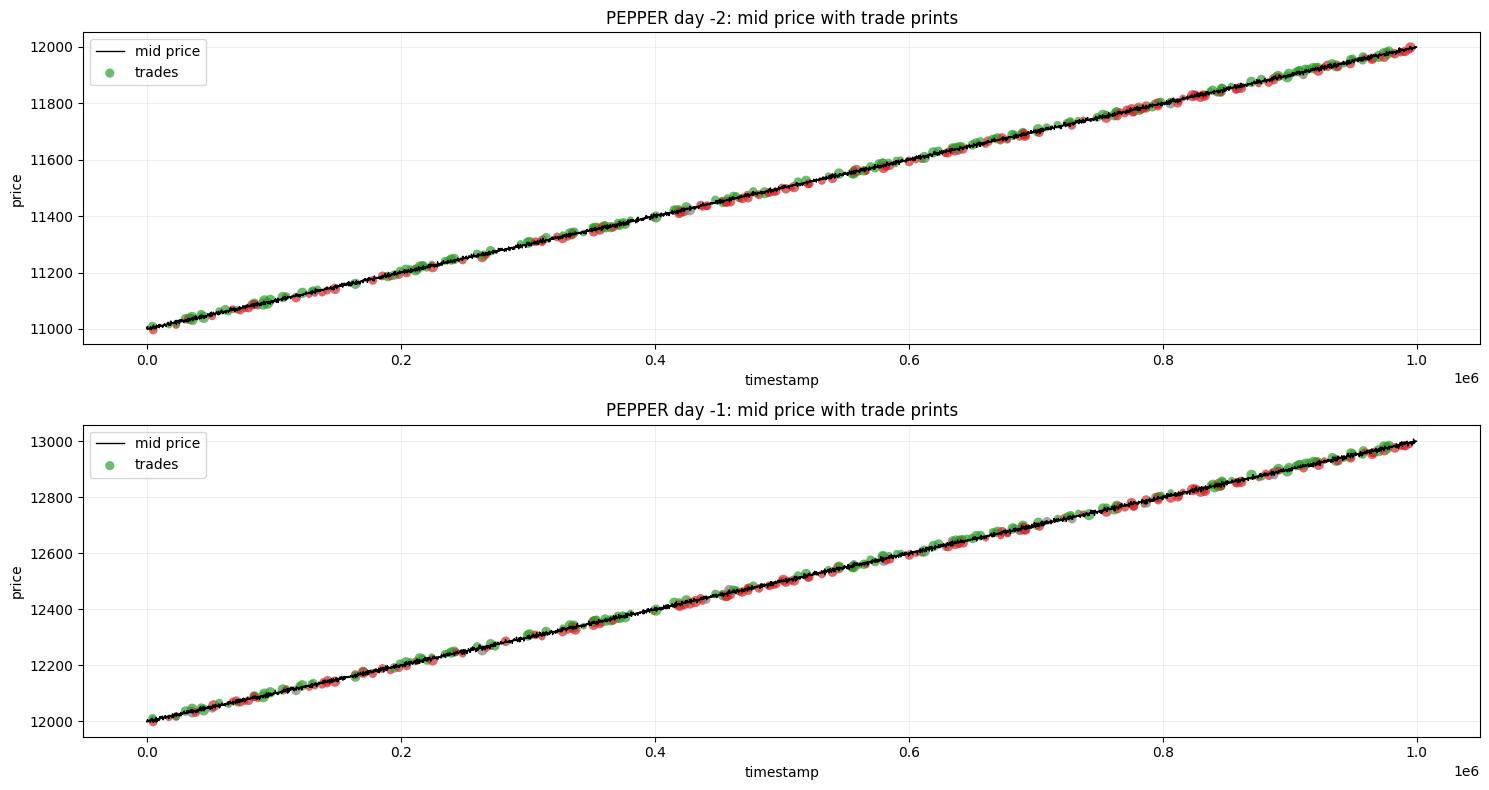

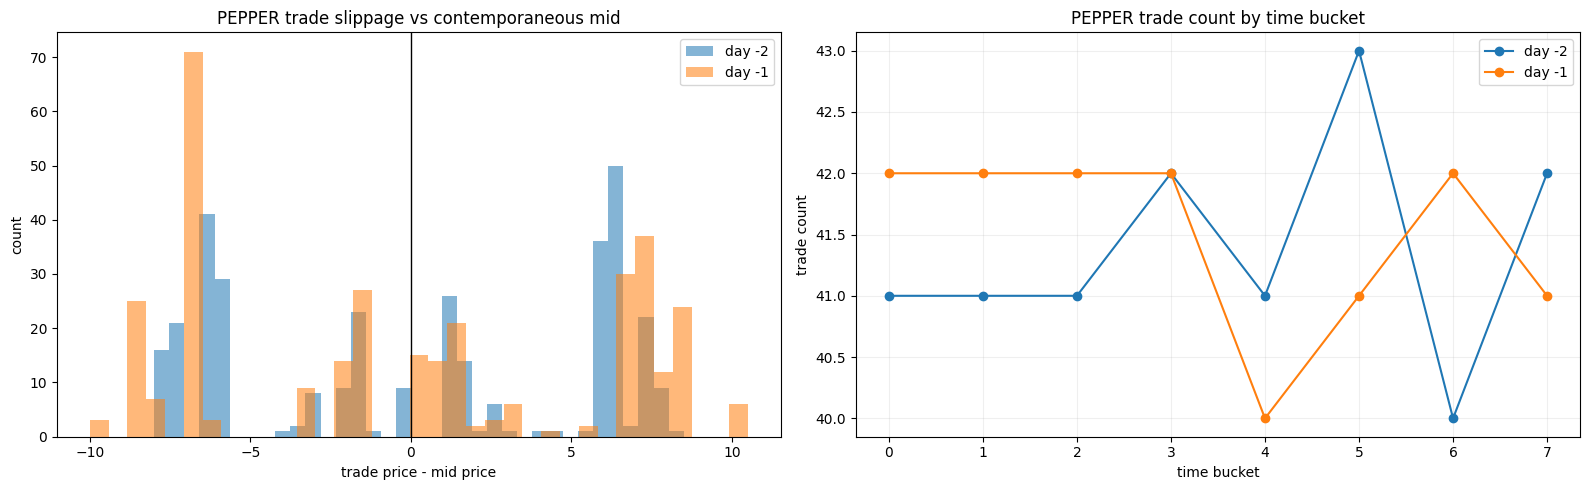

In [13]:
days = sorted(pepper_price["day"].dropna().unique().tolist())

fig, axes = plt.subplots(len(days), 1, figsize=(15, 4 * len(days)), sharex=False)
if len(days) == 1:
    axes = [axes]

for ax, day in zip(axes, days):
    price_day = pepper_price[pepper_price["day"] == day]
    trade_day = pepper_trades_ctx[pepper_trades_ctx["day"] == day]

    ax.plot(price_day["timestamp"], price_day["mid_price"], color="black", linewidth=1.0, label="mid price")
    if not trade_day.empty:
        colors = np.where(
            trade_day["trade_side_est"] == "buy_aggressive",
            "tab:green",
            np.where(trade_day["trade_side_est"] == "sell_aggressive", "tab:red", "tab:gray"),
        )
        sizes = np.clip(trade_day["quantity"].abs() * 8, 20, 220)
        ax.scatter(trade_day["timestamp"], trade_day["price"], s=sizes, c=colors, alpha=0.7, edgecolors="none", label="trades")

    ax.set_title(f"PEPPER day {day}: mid price with trade prints")
    ax.set_xlabel("timestamp")
    ax.set_ylabel("price")
    ax.grid(alpha=0.2)
    ax.legend(loc="best")

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for day in days:
    slippage_day = pepper_trades_ctx[pepper_trades_ctx["day"] == day]["slippage_vs_mid"].dropna()
    axes[0].hist(slippage_day, bins=35, alpha=0.55, label=f"day {day}")
axes[0].axvline(0, color="black", linewidth=1)
axes[0].set_title("PEPPER trade slippage vs contemporaneous mid")
axes[0].set_xlabel("trade price - mid price")
axes[0].set_ylabel("count")
axes[0].legend()

time_counts = pepper_trades_ctx.groupby(["day", "time_bucket"]).size().reset_index(name="trade_count")
for day in days:
    subset = time_counts[time_counts["day"] == day]
    axes[1].plot(subset["time_bucket"], subset["trade_count"], marker="o", label=f"day {day}")
axes[1].set_title("PEPPER trade count by time bucket")
axes[1].set_xlabel("time bucket")
axes[1].set_ylabel("trade count")
axes[1].legend()
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()

## Trend and residual diagnostics (from PEPPER analysis)
These metrics characterize how linear the day is and how residual pullbacks/extensions behave.

In [14]:
diag_rows = []
fit_by_day = {}
resid_by_day = {}

for day in days:
    d = pepper_price[pepper_price["day"] == day].sort_values("timestamp").copy()
    t = d["timestamp"].to_numpy(dtype=float)
    y = d["mid_price"].to_numpy(dtype=float)

    slope, intercept = np.polyfit(t, y, 1)
    y_hat = slope * t + intercept
    resid = y - y_hat

    ss_res = float(np.sum((y - y_hat) ** 2))
    ss_tot = float(np.sum((y - np.mean(y)) ** 2))
    r2 = 1.0 - ss_res / ss_tot if ss_tot > 0 else np.nan

    fit_by_day[day] = y_hat
    resid_by_day[day] = resid

    diag_rows.append({
        "day": int(day),
        "n": int(len(d)),
        "start_mid": float(y[0]),
        "end_mid": float(y[-1]),
        "slope_per_10k_ts": float(slope * 10000),
        "r2_linear": float(r2),
        "resid_std": float(np.std(resid)),
        "resid_q95_abs": float(np.quantile(np.abs(resid), 0.95)),
        "ret1_autocorr": float(pd.Series(d["ret_1"]).autocorr(lag=1)),
    })

pepper_diag = pd.DataFrame(diag_rows).sort_values("day").reset_index(drop=True)
pepper_diag.round(6)

,day,n,start_mid,end_mid,slope_per_10k_ts,r2_linear,resid_std,resid_q95_abs,ret1_autocorr
0,-2,9987,11001.5,11999.5,9.999958,0.999942,2.194477,6.175745,-0.497590
1,-1,9982,11998.5,13000.0,9.999791,0.999933,2.364049,6.688676,-0.489466


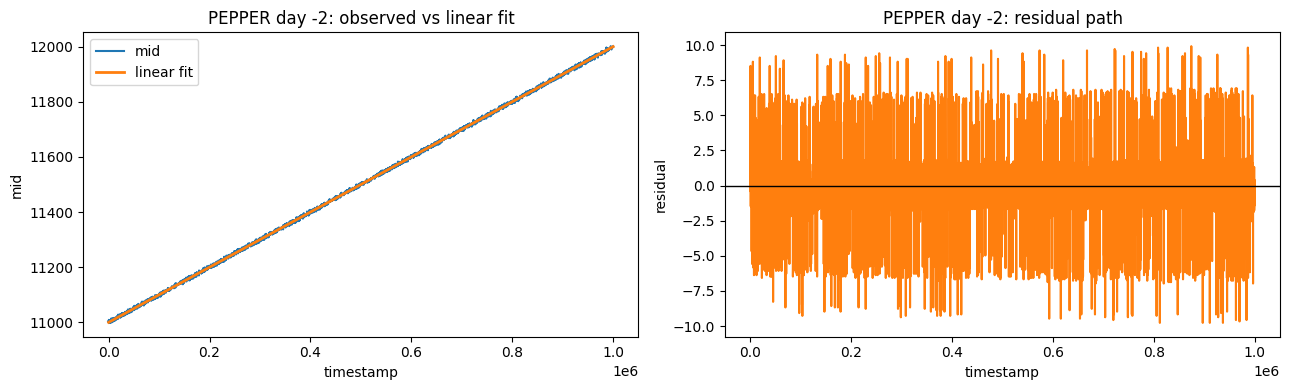

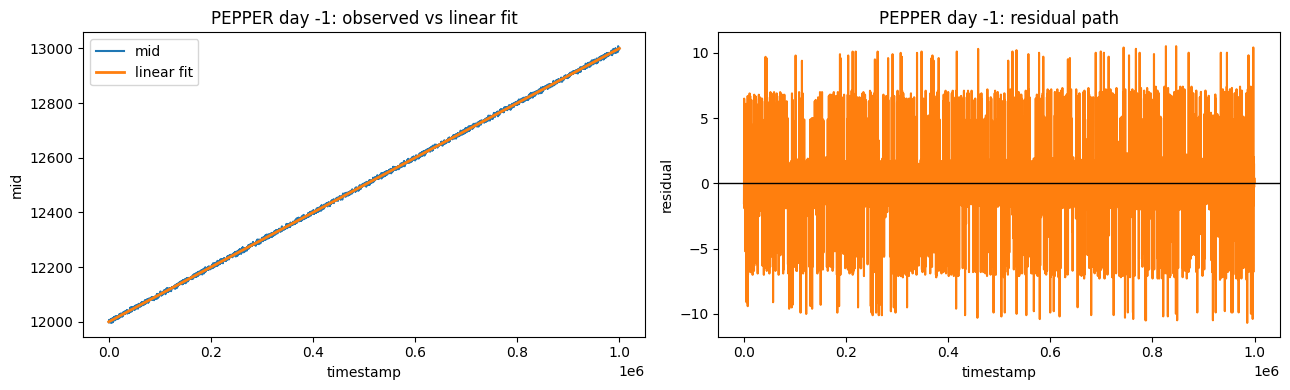

In [15]:
for day in days:
    d = pepper_price[pepper_price["day"] == day].sort_values("timestamp")
    y_hat = fit_by_day[day]
    resid = resid_by_day[day]

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))

    axes[0].plot(d["timestamp"], d["mid_price"], label="mid")
    axes[0].plot(d["timestamp"], y_hat, label="linear fit", linewidth=2)
    axes[0].set_title(f"PEPPER day {day}: observed vs linear fit")
    axes[0].set_xlabel("timestamp")
    axes[0].set_ylabel("mid")
    axes[0].legend()

    axes[1].plot(d["timestamp"], resid, color="tab:orange")
    axes[1].axhline(0, color="black", linewidth=1)
    axes[1].set_title(f"PEPPER day {day}: residual path")
    axes[1].set_xlabel("timestamp")
    axes[1].set_ylabel("residual")

    plt.tight_layout()
    plt.show()

## Pullback vs extension event study
Use residual z-score events to test whether dips below trend or extensions above trend have better forward expectancy.

In [16]:
horizons = [10, 25, 50, 100]
z_thresholds = [1.0, 1.5, 2.0, 2.5]
event_rows = []

for day in days:
    d = pepper_price[pepper_price["day"] == day].sort_values("timestamp")
    y = d["mid_price"].to_numpy(dtype=float)
    resid = resid_by_day[day]

    resid_std = float(np.std(resid))
    z = resid / resid_std if resid_std > 1e-12 else np.zeros_like(resid)

    for thr in z_thresholds:
        pull_idx = np.where(z <= -thr)[0]
        ext_idx = np.where(z >= thr)[0]

        row = {
            "day": int(day),
            "z_threshold": float(thr),
            "n_pullback": int(len(pull_idx)),
            "n_extension": int(len(ext_idx)),
        }

        for h in horizons:
            valid_pull = pull_idx[pull_idx + h < len(y)]
            valid_ext = ext_idx[ext_idx + h < len(y)]

            if len(valid_pull):
                pull_ret = (y[valid_pull + h] - y[valid_pull]) / y[valid_pull]
                row[f"pull_ret_{h}"] = float(np.mean(pull_ret))
                row[f"pull_pos_{h}"] = float(np.mean(pull_ret > 0))
            else:
                row[f"pull_ret_{h}"] = np.nan
                row[f"pull_pos_{h}"] = np.nan

            if len(valid_ext):
                ext_ret = (y[valid_ext + h] - y[valid_ext]) / y[valid_ext]
                row[f"ext_ret_{h}"] = float(np.mean(ext_ret))
                row[f"ext_pos_{h}"] = float(np.mean(ext_ret > 0))
            else:
                row[f"ext_ret_{h}"] = np.nan
                row[f"ext_pos_{h}"] = np.nan

        event_rows.append(row)

pepper_event = pd.DataFrame(event_rows).sort_values(["day", "z_threshold"]).reset_index(drop=True)

focus_cols = [
    "day",
    "z_threshold",
    "n_pullback",
    "n_extension",
    "pull_ret_50",
    "pull_pos_50",
    "ext_ret_50",
    "ext_pos_50",
]
pepper_event[focus_cols].round(6)

,day,z_threshold,n_pullback,n_extension,pull_ret_50,pull_pos_50,ext_ret_50,ext_pos_50
0,-2,1.0,575,521,0.000966,1.0,-0.000106,0.250000
1,-2,1.5,541,510,0.000988,1.0,-0.000111,0.235756
2,-2,2.0,530,494,0.000991,1.0,-0.000116,0.221095
3,-2,2.5,405,380,0.001013,1.0,-0.000150,0.105541
4,-1,1.0,554,552,0.000928,1.0,-0.000122,0.103448
5,-1,1.5,513,544,0.000948,1.0,-0.000124,0.093923
6,-1,2.0,493,531,0.000956,1.0,-0.000128,0.084906
7,-1,2.5,381,406,0.000990,1.0,-0.000167,0.049383


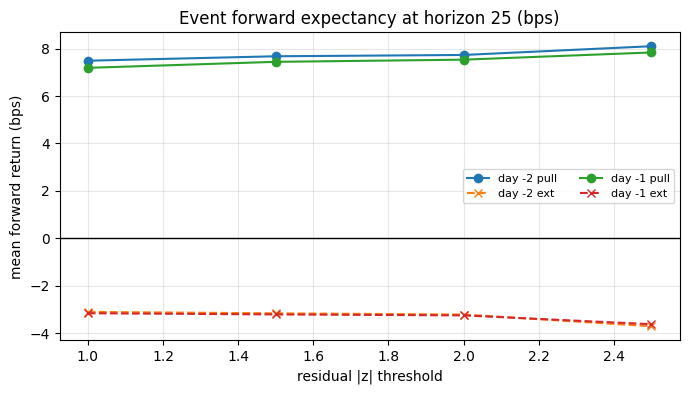

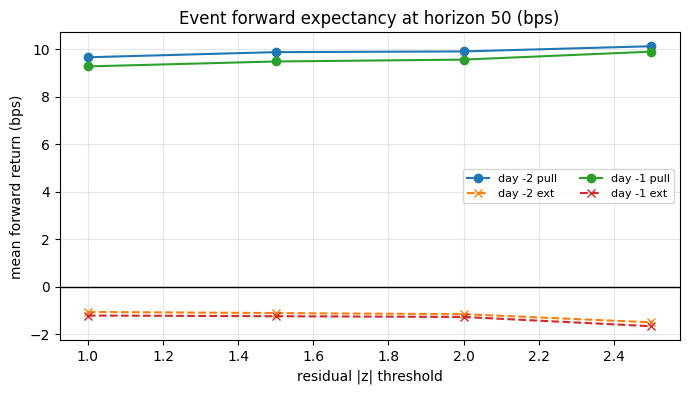

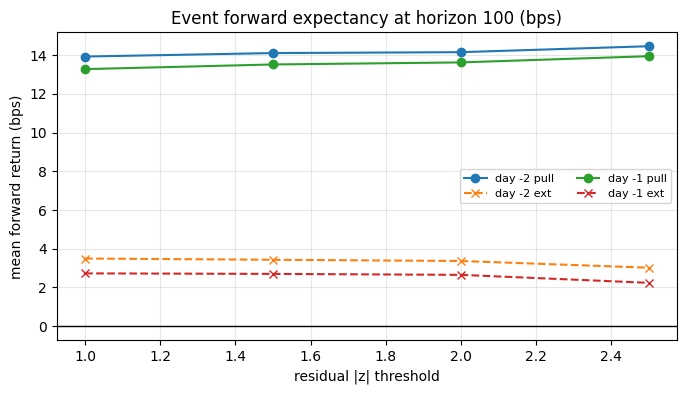

In [17]:
for h in [25, 50, 100]:
    plt.figure(figsize=(8, 4))
    for day in days:
        sub = pepper_event[pepper_event["day"] == day]
        plt.plot(sub["z_threshold"], sub[f"pull_ret_{h}"] * 1e4, marker="o", label=f"day {day} pull")
        plt.plot(sub["z_threshold"], sub[f"ext_ret_{h}"] * 1e4, marker="x", linestyle="--", label=f"day {day} ext")
    plt.axhline(0, color="black", linewidth=1)
    plt.title(f"Event forward expectancy at horizon {h} (bps)")
    plt.xlabel("residual |z| threshold")
    plt.ylabel("mean forward return (bps)")
    plt.grid(alpha=0.3)
    plt.legend(ncol=2, fontsize=8)
    plt.show()

## Execution-adjusted edge scorecard
Translate event-study expectancy to net edge after spread costs.

In [18]:
cost_rows = []

for day in days:
    d = pepper_price[pepper_price["day"] == day]
    mean_mid = float(d["mid_price"].mean())
    mean_spread = float(np.nanmean(d["spread_1"]))
    half_spread_bps = (mean_spread / 2.0) / mean_mid * 1e4 if mean_mid > 0 else np.nan

    sub = pepper_event[pepper_event["day"] == day]
    for _, r in sub.iterrows():
        for h in [25, 50, 100]:
            pull_bps = r[f"pull_ret_{h}"] * 1e4 if pd.notna(r[f"pull_ret_{h}"]) else np.nan
            ext_bps = r[f"ext_ret_{h}"] * 1e4 if pd.notna(r[f"ext_ret_{h}"]) else np.nan

            cost_rows.append({
                "day": int(day),
                "z_threshold": float(r["z_threshold"]),
                "horizon": int(h),
                "half_spread_cost_bps": half_spread_bps,
                "pull_gross_bps": pull_bps,
                "pull_net_bps": pull_bps - half_spread_bps if pd.notna(pull_bps) else np.nan,
                "ext_gross_bps": ext_bps,
                "ext_net_bps": ext_bps - half_spread_bps if pd.notna(ext_bps) else np.nan,
            })

scorecard = pd.DataFrame(cost_rows).sort_values(["day", "horizon", "z_threshold"]).reset_index(drop=True)

best_pull = scorecard.sort_values("pull_net_bps", ascending=False).head(12)
best_ext = scorecard.sort_values("ext_net_bps", ascending=False).head(12)

display(scorecard.round(4))
display(best_pull.round(4))
display(best_ext.round(4))

,day,z_threshold,horizon,half_spread_cost_bps,pull_gross_bps,pull_net_bps,ext_gross_bps,ext_net_bps
0,-2,1.0,25,5.6811,7.4868,1.8057,-3.1102,-8.7913
1,-2,1.5,25,5.6811,7.6742,1.9930,-3.1719,-8.8530
2,-2,2.0,25,5.6811,7.7291,2.0479,-3.2216,-8.9027
3,-2,2.5,25,5.6811,8.0979,2.4168,-3.7156,-9.3967
4,-2,1.0,50,5.6811,9.6608,3.9797,-1.0646,-6.7457
5,-2,1.5,50,5.6811,9.8770,4.1958,-1.1119,-6.7931
6,-2,2.0,50,5.6811,9.9067,4.2255,-1.1585,-6.8397
7,-2,2.5,50,5.6811,10.1258,4.4446,-1.5025,-7.1836
8,-2,1.0,100,5.6811,13.9266,8.2454,3.4963,-2.1848
9,-2,1.5,100,5.6811,14.1061,8.4250,3.4318,-2.2494


,day,z_threshold,horizon,half_spread_cost_bps,pull_gross_bps,pull_net_bps,ext_gross_bps,ext_net_bps
11,-2,2.5,100,5.6811,14.4596,8.7785,3.0226,-2.6585
10,-2,2.0,100,5.6811,14.1520,8.4709,3.3694,-2.3118
9,-2,1.5,100,5.6811,14.1061,8.4250,3.4318,-2.2494
23,-1,2.5,100,5.6485,13.9444,8.2960,2.2411,-3.4074
8,-2,1.0,100,5.6811,13.9266,8.2454,3.4963,-2.1848
22,-1,2.0,100,5.6485,13.6235,7.9751,2.6528,-2.9957
21,-1,1.5,100,5.6485,13.5175,7.8691,2.7025,-2.9459
20,-1,1.0,100,5.6485,13.2773,7.6289,2.7289,-2.9195
7,-2,2.5,50,5.6811,10.1258,4.4446,-1.5025,-7.1836
19,-1,2.5,50,5.6485,9.8980,4.2495,-1.6660,-7.3144


,day,z_threshold,horizon,half_spread_cost_bps,pull_gross_bps,pull_net_bps,ext_gross_bps,ext_net_bps
8,-2,1.0,100,5.6811,13.9266,8.2454,3.4963,-2.1848
9,-2,1.5,100,5.6811,14.1061,8.4250,3.4318,-2.2494
10,-2,2.0,100,5.6811,14.1520,8.4709,3.3694,-2.3118
11,-2,2.5,100,5.6811,14.4596,8.7785,3.0226,-2.6585
20,-1,1.0,100,5.6485,13.2773,7.6289,2.7289,-2.9195
21,-1,1.5,100,5.6485,13.5175,7.8691,2.7025,-2.9459
22,-1,2.0,100,5.6485,13.6235,7.9751,2.6528,-2.9957
23,-1,2.5,100,5.6485,13.9444,8.2960,2.2411,-3.4074
4,-2,1.0,50,5.6811,9.6608,3.9797,-1.0646,-6.7457
5,-2,1.5,50,5.6811,9.8770,4.1958,-1.1119,-6.7931
